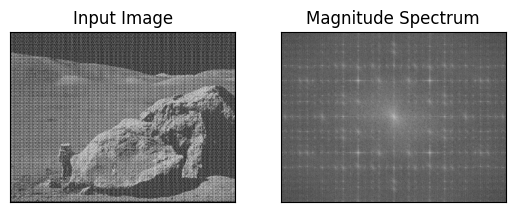

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

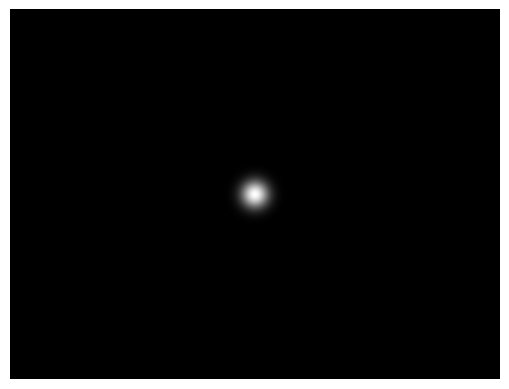

In [2]:
size = 15
rows, cols = img.shape

x, y = np.meshgrid(np.arange(cols), np.arange(rows))
r = (x - cols//2)**2 + (y - rows//2)**2

H = np.exp(-r / (2 * size**2))

plt.axis('off')
plt.imshow(H, cmap = 'gray')

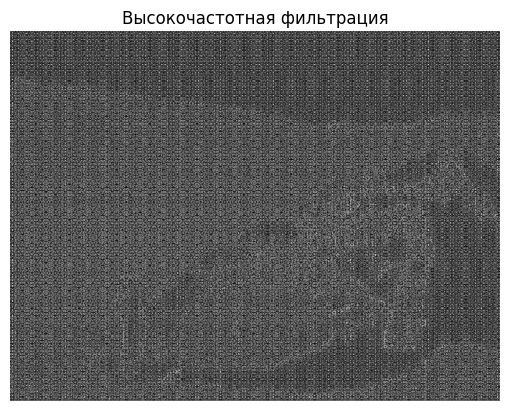

In [3]:
mask_gauss = 1 - H
dft_shift_gauss = dft_shift * mask_gauss[:, :, np.newaxis]

f_ishift = np.fft.ifftshift(dft_shift_gauss)
img_gauss = cv.idft(f_ishift)
img_gauss_final = cv.magnitude(img_gauss[:,:,0], img_gauss[:,:,1])

plt.title('Высокочастотная фильтрация')
plt.axis('off')
plt.imshow(img_gauss_final, cmap='gray')

# Реализуйте вычисление свертки с помощью преобразования Фурье

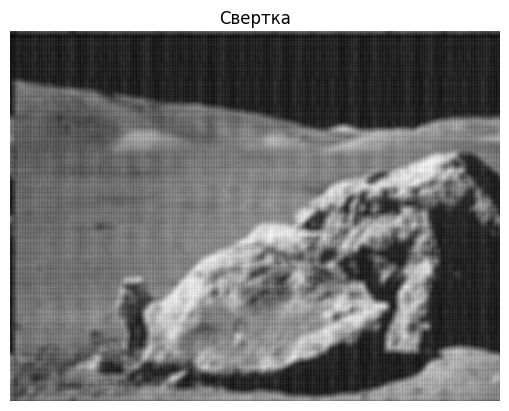

In [4]:
kernel = np.ones((11, 11), np.float32) / 121

F = np.fft.fft2(img,    s=(rows, cols))
H = np.fft.fft2(kernel, s=(rows, cols))
G = F * H
img_res = np.real(np.fft.ifft2(G))

plt.title('Свертка')
plt.axis('off')
plt.imshow(img_res, cmap='gray')

# Реализуйте удаление периодического шума с помощью преобразования Фурье

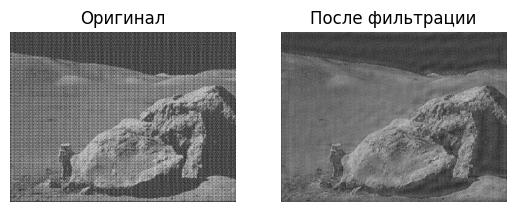

In [5]:
magnitude = cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1])

cy, cx = rows // 2, cols // 2
magnitude[cy-15:cy+15, cx-15:cx+15] = 0

peaks = np.argwhere(magnitude > np.percentile(magnitude, 99.8))

dft_shift_copy = dft_shift.copy()
for py, px in peaks:
    dft_shift_copy[max(0, py-3):py+4, max(0, px-3):px+4, :] = 0

f_ishift = np.fft.ifftshift(dft_shift_copy)
img_f = cv.idft(f_ishift)
img_final = cv.magnitude(img_f[:,:,0], img_f[:,:,1])

plt.subplot(121), plt.imshow(img, cmap = 'gray')
plt.title('Оригинал'), plt.axis('off')
plt.subplot(122), plt.imshow(img_final, cmap = 'gray')
plt.title('После фильтрации'), plt.axis('off')
plt.show()